# 04 · Generative AI: synthetic transaction feature vectors

The trained E1 decoder turns random latent vectors into new feature vectors:

1. Sample $z \sim \mathcal{N}(0, I)$ from the prior.
2. Decode to $\hat x(z)$ in standardised space.
3. Apply the saved inverse transformation (un-standardise, `expm1` for Amount, clip at 0, round to 2 decimals).
4. Export to CSV in `data/synthetic/`, separate from the original data, with **no fraud label**.

There are two samplers, both evaluated the same way. Neither was chosen using test data.
- **Decoder mean (primary, pre-registered):** $x = \hat x(z)$.
- **Decoder mean + fitted noise (pre-listed variant):** $x = \hat x(z) + \varepsilon$, with $\varepsilon \sim \mathcal{N}(0, \operatorname{diag}(\sigma^2))$. Here $\sigma$ is the decoder's noise level, estimated from **training** reconstruction residuals. This draws a full sample from $p(x \mid z)$ instead of only its mean.

The real reference is the **42,647 normal test transactions**, held out from training, early stopping and threshold calibration.

> **Important:** generated samples are vectors in the dataset's **anonymised PCA feature space** (`V1`–`V28` plus `Amount`). They are not interpretable merchant or customer transaction records and must not be presented as verified real-world transactions.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/genAI")  # change this if the project folder lives elsewhere on Drive
else:
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROJECT_ROOT = PROJECT_ROOT.resolve()
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".cache" / "matplotlib"))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT.name)

Project root: genAI


In [2]:
import subprocess
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image

from src.data.load import RAW_INPUT_COLUMNS, TARGET_COL, load_raw
from src.data.prepare import processed_dir
from src.data.preprocess import FeatureTransformer
from src.data.split import load_splits
from src.evaluation import generative_metrics as gm
from src.evaluation import model_plots as mp
from src.evaluation.plots import apply_style
from src.generation.sample import generate_synthetic
from src.training.run import load_trained_model, run_dir
from src.utils.io import load_config

pd.set_option("display.width", 200)
apply_style()
data_cfg = load_config(PROJECT_ROOT)
summary_path = PROJECT_ROOT / "outputs" / "metrics" / "generation_summary.json"
if not summary_path.exists():  # e.g. a fresh Colab runtime
    subprocess.run([sys.executable, str(PROJECT_ROOT / "scripts" / "generate_synthetic.py")], check=True, cwd=PROJECT_ROOT)
summary = json.loads(summary_path.read_text())
model = load_trained_model(run_dir(PROJECT_ROOT, "e1", 0), "cpu")
tf = FeatureTransformer.load(processed_dir(PROJECT_ROOT, data_cfg) / "transformer_e1.json")

## 1. Generating samples (configurable number, seed and temperature)

In [3]:
_, demo = generate_synthetic(model, tf, n=5, seed=123)
demo.round(3)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,-0.082,0.655,0.451,-0.018,0.171,-0.506,0.344,0.057,-0.121,-0.267,-0.002,0.264,-0.097,0.003,0.175,0.191,-0.238,-0.040,0.068,-0.063,-0.080,-0.195,-0.014,0.020,-0.108,0.095,0.031,0.030,8.47
1,-0.845,0.684,0.721,-0.356,0.296,-0.565,0.380,0.109,0.024,-0.286,-0.088,0.007,-0.030,0.029,-0.074,0.241,-0.313,0.113,-0.145,-0.065,-0.042,-0.119,-0.081,0.002,-0.099,0.046,0.053,0.050,9.27
2,-0.568,0.828,0.916,1.026,0.319,-0.036,0.306,0.154,-0.473,0.042,-0.187,0.098,-0.161,0.034,0.054,0.220,-0.354,0.173,-0.172,-0.050,0.090,0.198,-0.127,-0.079,-0.046,-0.175,0.007,0.016,14.19
3,0.839,-0.759,0.996,-1.073,-0.923,0.084,-1.021,0.077,0.275,0.512,0.649,-2.548,1.529,0.652,-1.090,-0.013,0.964,-0.032,-0.013,-0.238,-0.167,-0.082,-0.001,-0.044,0.039,-0.168,0.032,-0.012,26.01
4,-0.537,0.118,1.010,0.286,-0.156,-0.083,0.265,0.073,0.673,-0.562,0.460,-1.122,0.647,0.744,-0.086,-0.008,0.167,0.252,0.103,0.058,0.019,0.044,-0.029,-0.042,-0.078,0.163,-0.039,-0.005,56.22


## 2. The exported CSV files

In [4]:
for name, v in summary["variants"].items():
    path = PROJECT_ROOT / v["csv"]
    print(f"{name:26s} {path.relative_to(PROJECT_ROOT)}  ({path.stat().st_size / 1e6:.1f} MB)")
synth = {name: pd.read_csv(PROJECT_ROOT / v["csv"]) for name, v in summary["variants"].items()}
print("columns:", list(synth["decoder_mean"].columns), "| Class column present:", "Class" in synth["decoder_mean"].columns)
synth["decoder_mean"].head()

decoder_mean               data/synthetic/synthetic_e1_decoder_mean_n42647_seed0.csv  (11.8 MB)
decoder_mean_plus_noise    data/synthetic/synthetic_e1_decoder_mean_plus_noise_n42647_seed0.csv  (11.8 MB)
columns: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount'] | Class column present: False


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,-0.570534,0.963562,-0.475761,-0.210229,0.811079,-0.809810,0.963391,0.004342,-0.369325,-0.049426,-0.306794,0.103734,-0.266272,0.397107,-0.284170,-0.180824,-0.298262,0.084878,0.242921,-0.099480,0.156861,0.572279,-0.044682,0.012823,-0.049934,0.107435,-0.013975,0.035878,8.29
1,-0.788570,0.638603,0.482027,-0.319478,0.259261,-0.464990,0.402383,0.133458,-0.001989,-0.393629,-0.136785,0.202914,-0.167768,-0.059175,0.082045,0.194514,-0.301856,0.199189,-0.054006,-0.086362,0.034761,0.118569,-0.058399,-0.050510,-0.109417,-0.030275,0.012114,0.005360,14.63
2,-0.769845,0.565710,0.587134,0.303227,-0.135753,-0.114813,0.150409,0.218527,0.244188,-0.537204,-0.121107,0.332615,-0.195155,-0.798650,-0.531203,0.169635,0.394001,0.131319,0.036031,-0.146217,-0.030031,-0.041532,-0.056378,-0.062339,-0.070620,0.119689,-0.093323,-0.035495,21.89
3,-0.388650,0.803615,0.672496,0.513331,0.407454,-0.324214,0.427837,0.086862,-0.357354,-0.118746,-0.160368,0.172334,-0.171203,0.142415,0.094443,0.066944,-0.344012,0.120931,-0.020194,-0.051612,0.070088,0.181024,-0.106181,-0.031866,-0.034299,-0.156355,0.057864,0.049763,9.82
4,0.056795,0.387190,0.604549,0.333800,-0.052828,-0.296769,0.182354,0.100742,0.039141,-0.290273,-0.034081,0.320702,-0.177605,0.008971,0.204905,0.103947,-0.206608,0.029719,0.074967,-0.055594,-0.014156,-0.012493,-0.043662,-0.000103,0.004346,-0.010599,0.015065,0.014341,18.75


In [5]:
df = load_raw(PROJECT_ROOT, data_cfg)
splits, _ = load_splits(processed_dir(PROJECT_ROOT, data_cfg) / "splits.json")
y_all = df[TARGET_COL].to_numpy()
real = df.iloc[splits["test"][y_all[splits["test"]] == 0]][RAW_INPUT_COLUMNS].reset_index(drop=True)
print(f"Real reference: {len(real):,} normal test transactions | synthetic per sampler: {len(synth['decoder_mean']):,}")

Real reference: 42,647 normal test transactions | synthetic per sampler: 42,647


## 3. Quantitative comparison

In [6]:
pd.read_csv(PROJECT_ROOT / "outputs" / "metrics" / "generation_comparison.csv", index_col=0).round(4)

,mean_KS,mean_W1,std_ratio_V,tail_width_ratio,corr_frobenius,C2ST_logreg,C2ST_gboost,DCR_median
sampler,,,,,,,,
decoder_mean,0.2211,0.3750,0.490,0.5462,3.8033,0.5901,0.9999,1.8906
decoder_mean_plus_noise,0.0533,0.0958,0.838,0.7664,1.6186,0.5494,0.9908,3.1006
real vs real (reference),0.0060,0.0113,NaN,NaN,NaN,0.5030,0.5030,NaN


Column guide:
- **`mean_KS` / `mean_W1`:** average per-feature Kolmogorov–Smirnov statistic and Wasserstein-1 distance (standardised units). 0 means identical.
- **`std_ratio_V`:** synthetic std ÷ real std, averaged over V1–V28 (1 is ideal).
- **`tail_width_ratio`:** width of the 0.1–99.9% range, synthetic ÷ real (median over features).
- **`corr_frobenius`:** size of the correlation-matrix difference.
- **`C2ST_*`:** ROC-AUC of a classifier trained to tell real from synthetic (0.5 means indistinguishable).
- **`DCR_median`:** median distance from a synthetic row to its closest training row. The real held-out value is 0.89.

The **real vs real** row compares two real normal samples, so it shows the noise floor.

In [7]:
moments = gm.moment_table(real, synth["decoder_mean"])
moments.round(3).head(10)

,real_mean,synthetic_mean,real_std,synthetic_std,mean_diff_in_real_std,std_ratio
V1,0.003,0.106,1.958,1.140,0.053,0.583
V2,-0.009,0.042,1.672,0.963,0.030,0.576
V3,0.018,0.122,1.452,0.783,0.071,0.539
V4,0.001,0.022,1.408,0.915,0.015,0.650
V5,-0.002,-0.008,1.335,0.791,-0.005,0.592
V6,-0.002,-0.051,1.321,0.886,-0.037,0.670
V7,0.013,0.067,1.154,0.559,0.046,0.484
V8,-0.001,0.056,1.149,0.497,0.049,0.433
V9,0.016,-0.089,1.098,0.695,-0.096,0.633
V10,0.012,-0.005,1.073,0.618,-0.016,0.575


## 4. Visual comparison: primary sampler (decoder mean)

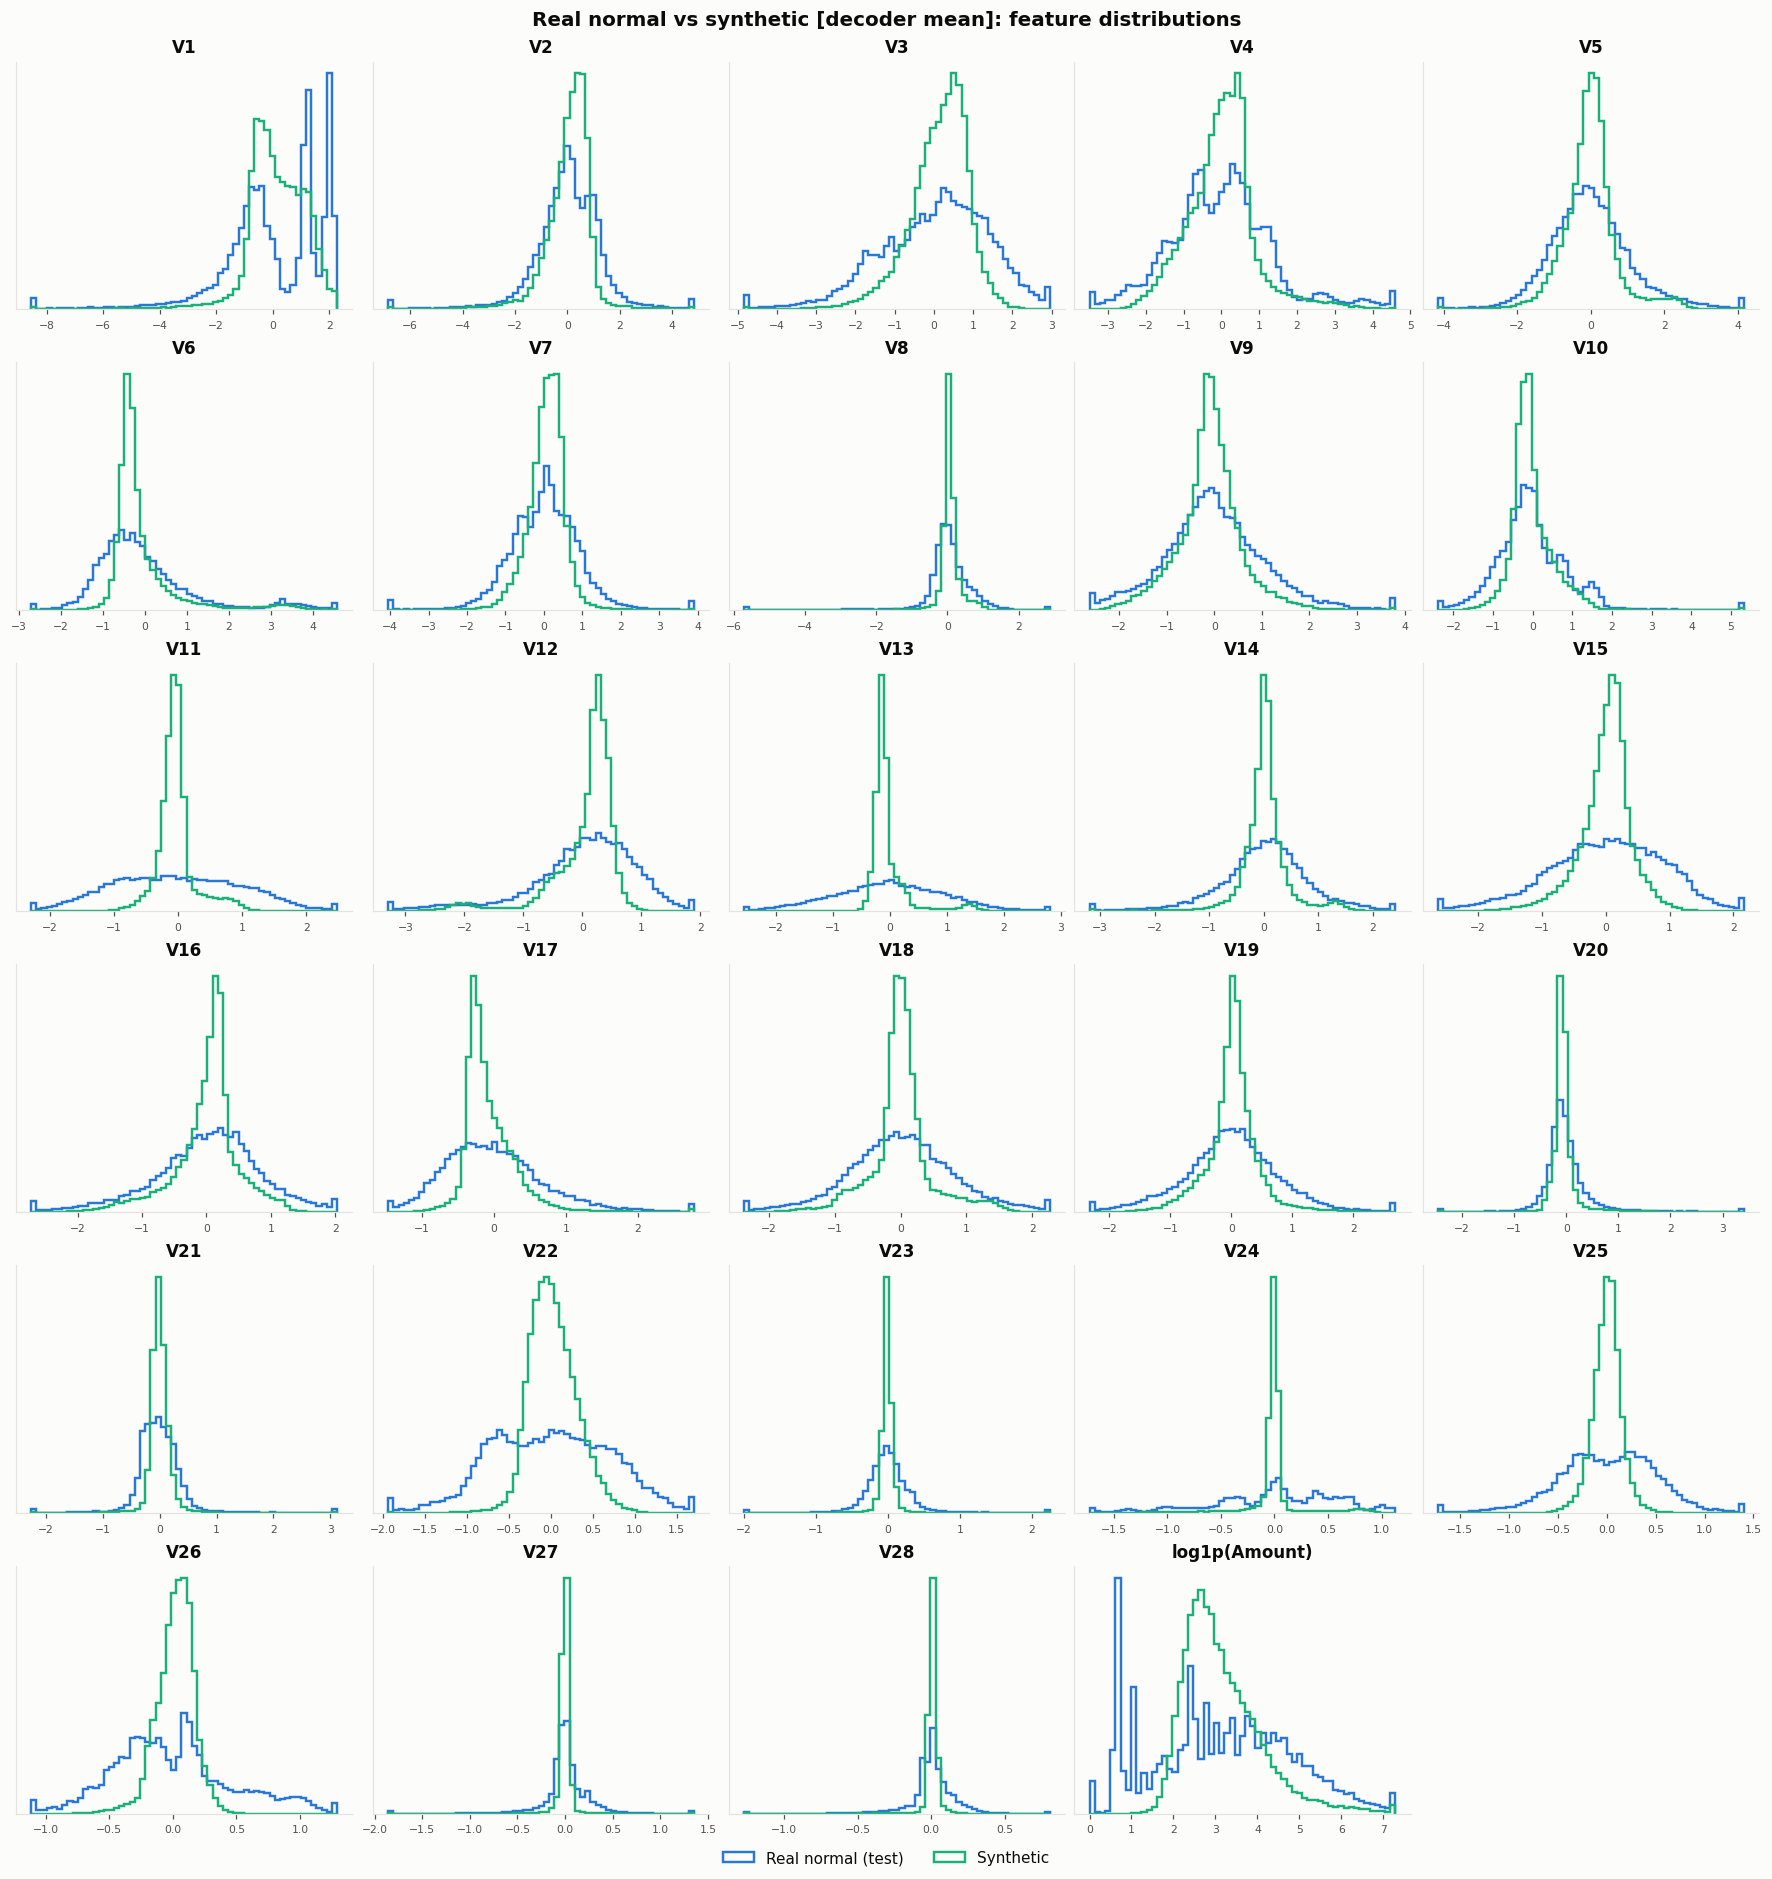

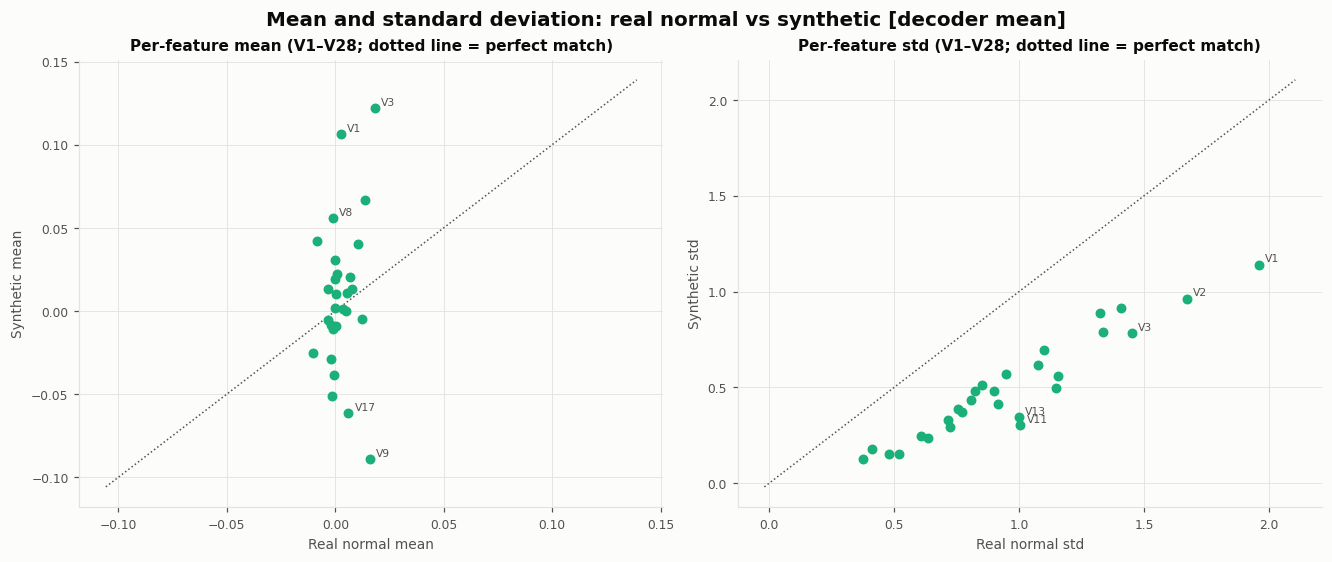

In [8]:
mp.plot_real_vs_synthetic_grid(real, synth["decoder_mean"], "Real normal vs synthetic [decoder mean]: feature distributions")
plt.show()
mp.plot_moment_comparison(moments, "Mean and standard deviation: real normal vs synthetic [decoder mean]")
plt.show()

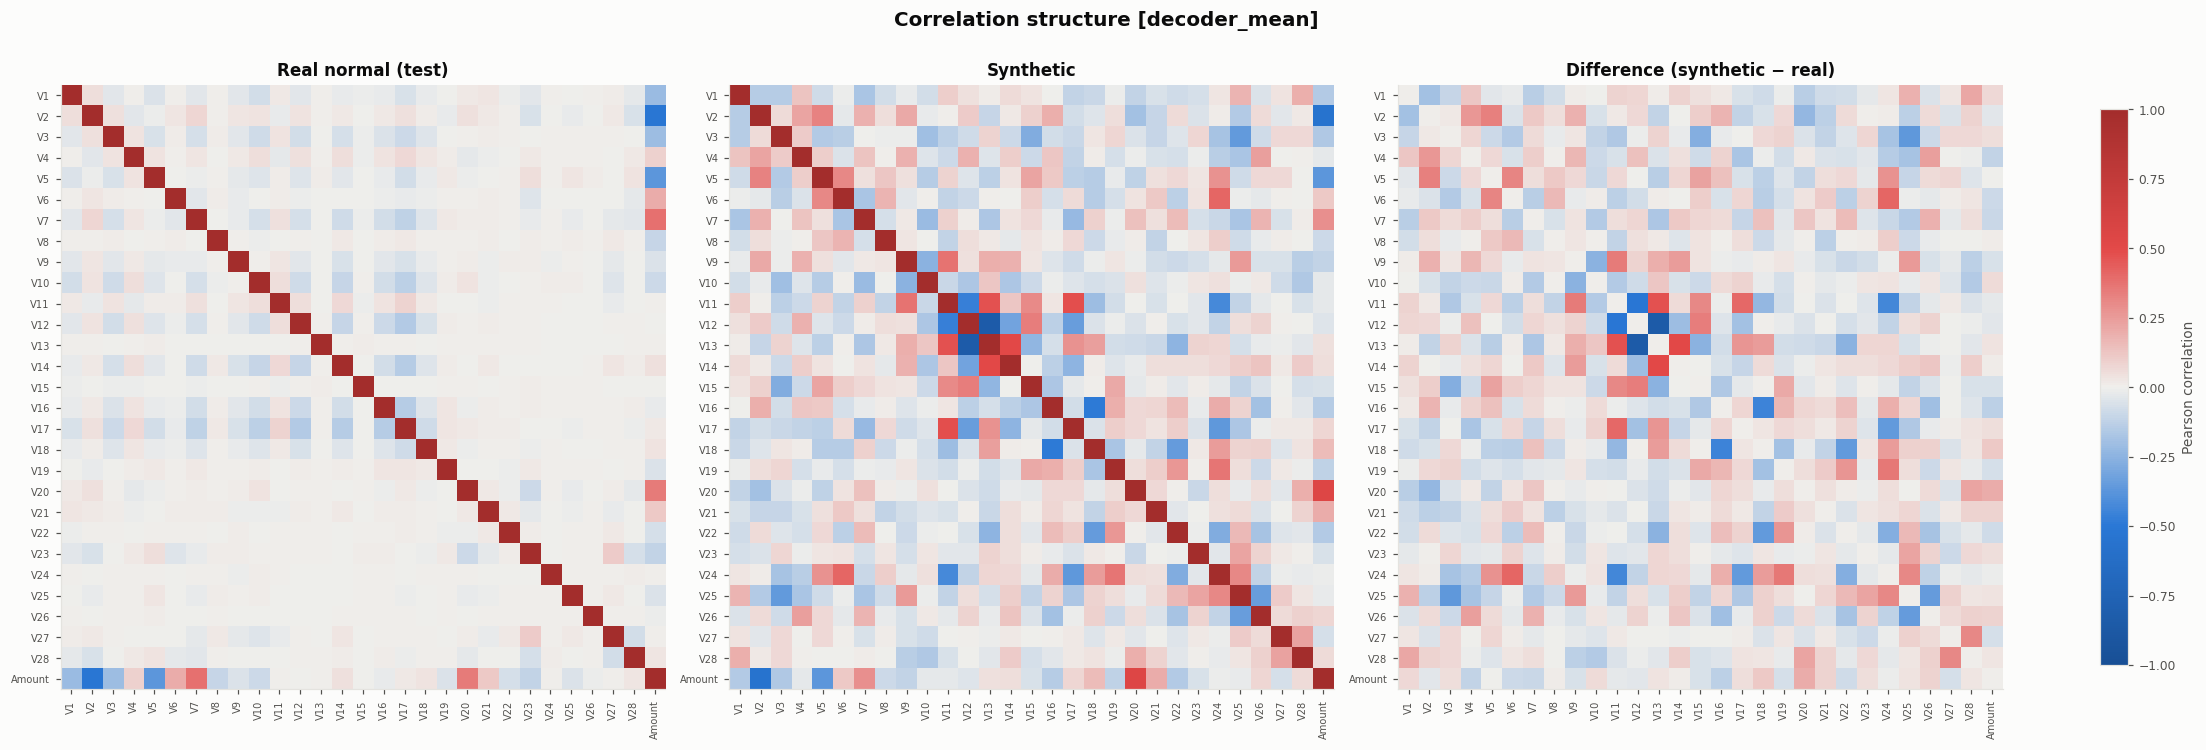

decoder_mean | Amount correlations (real vs synthetic): {'Amount~V2': (-0.52, -0.56), 'Amount~V5': (-0.37, -0.37), 'Amount~V7': (0.38, 0.28), 'Amount~V20': (0.35, 0.54), 'Amount~V1': (-0.22, -0.15)}


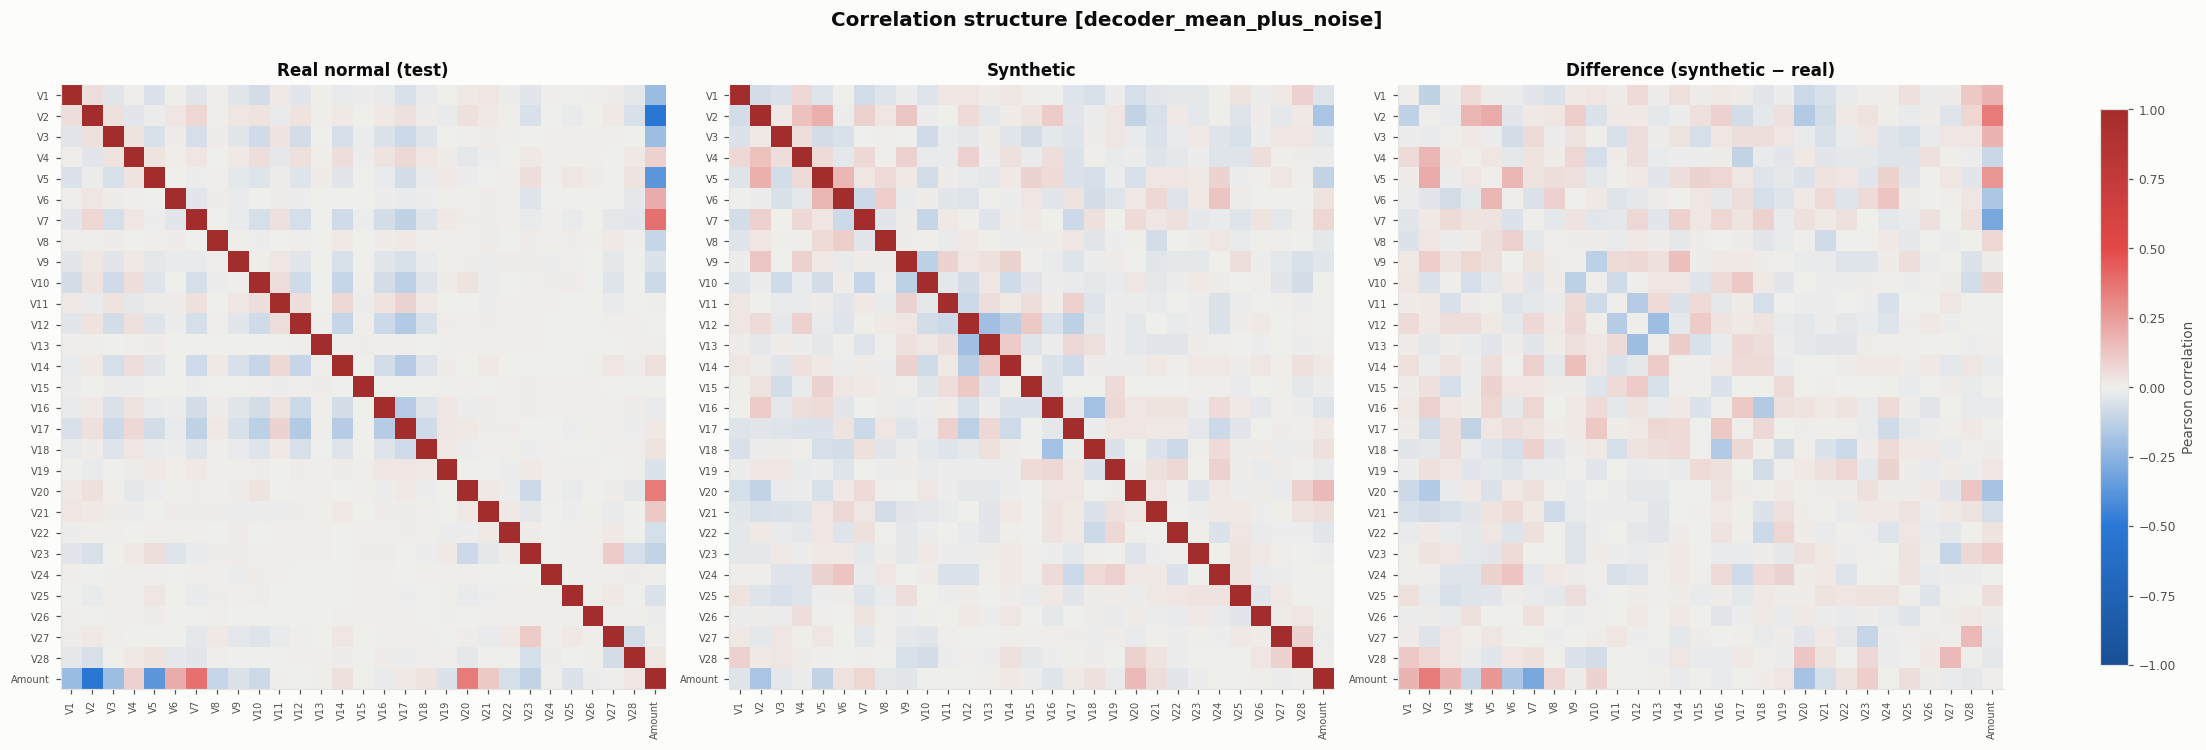

decoder_mean_plus_noise | Amount correlations (real vs synthetic): {'Amount~V2': (-0.52, -0.17), 'Amount~V5': (-0.37, -0.11), 'Amount~V7': (0.38, 0.07), 'Amount~V20': (0.35, 0.16), 'Amount~V1': (-0.22, -0.04)}


In [9]:
for name in synth:
    corr = gm.correlation_comparison(real, synth[name])
    mp.plot_correlation_comparison(corr, list(real.columns), f"Correlation structure [{name}]")
    plt.show()
    print(name, "| Amount correlations (real vs synthetic):",
          {k: (round(v["real"], 2), round(v["synthetic"], 2)) for k, v in corr["amount_correlations"].items()})

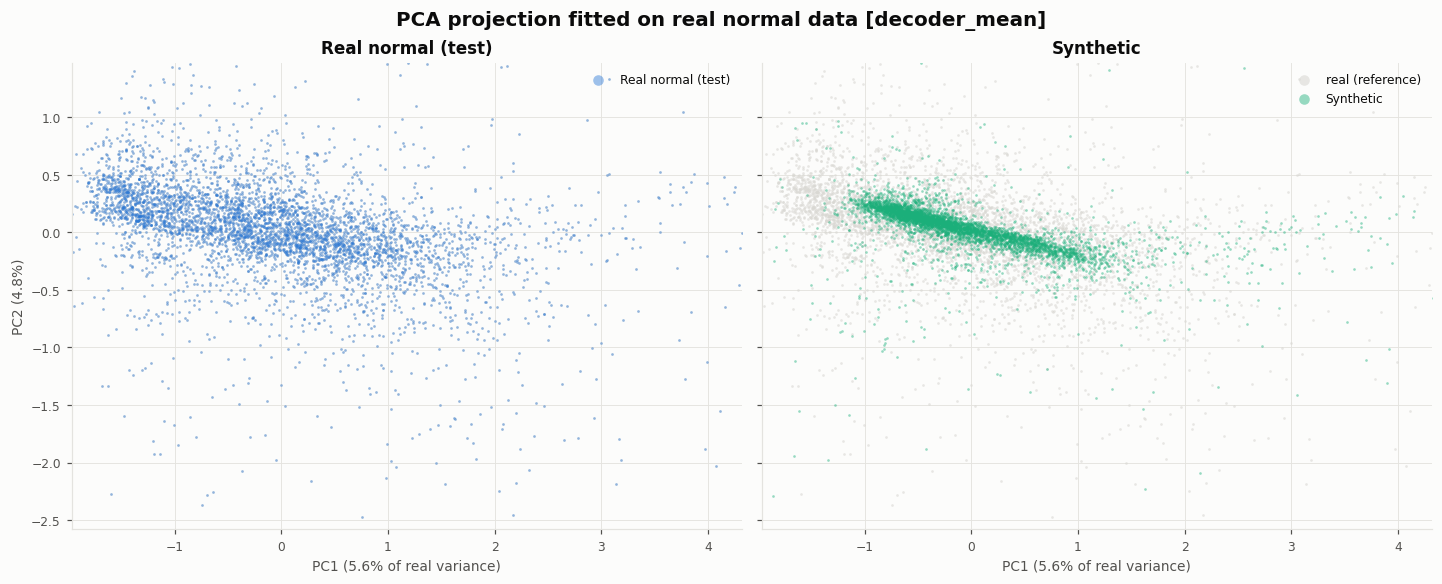

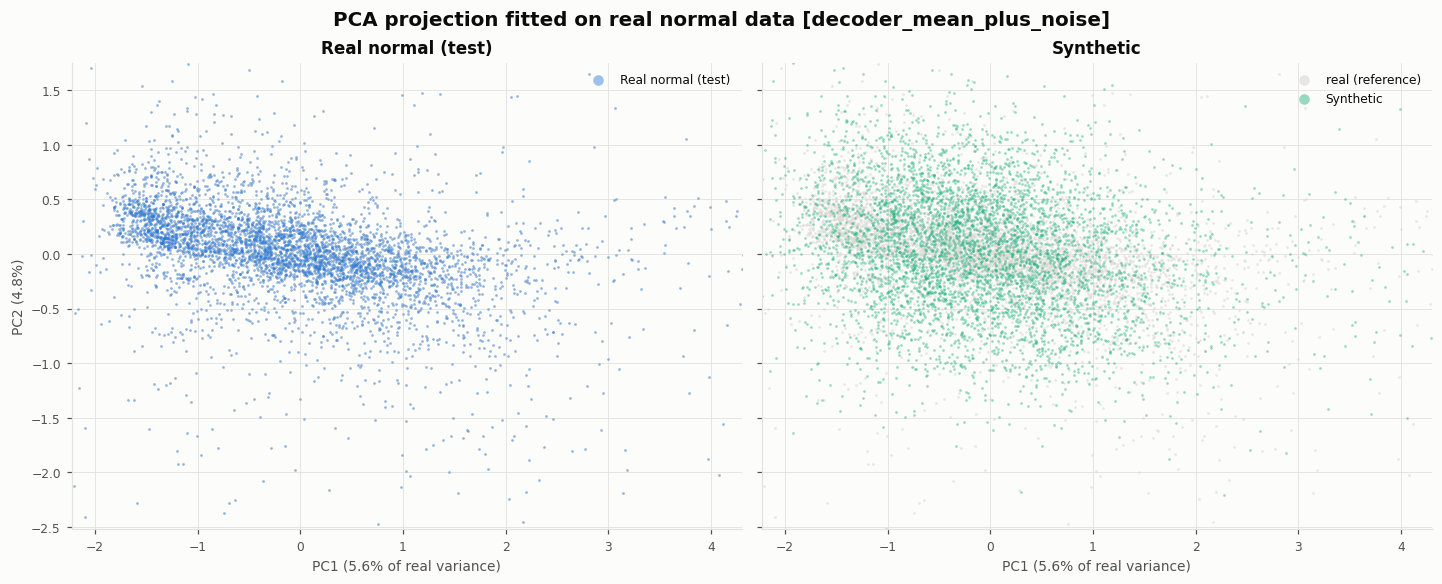

In [10]:
for name in synth:
    proj = gm.pca_projection(tf.transform(real), tf.transform(synth[name]))
    mp.plot_pca_overlay(proj, f"PCA projection fitted on real normal data [{name}]")
    plt.show()

## 5. Visual comparison: variant (decoder mean + fitted noise)

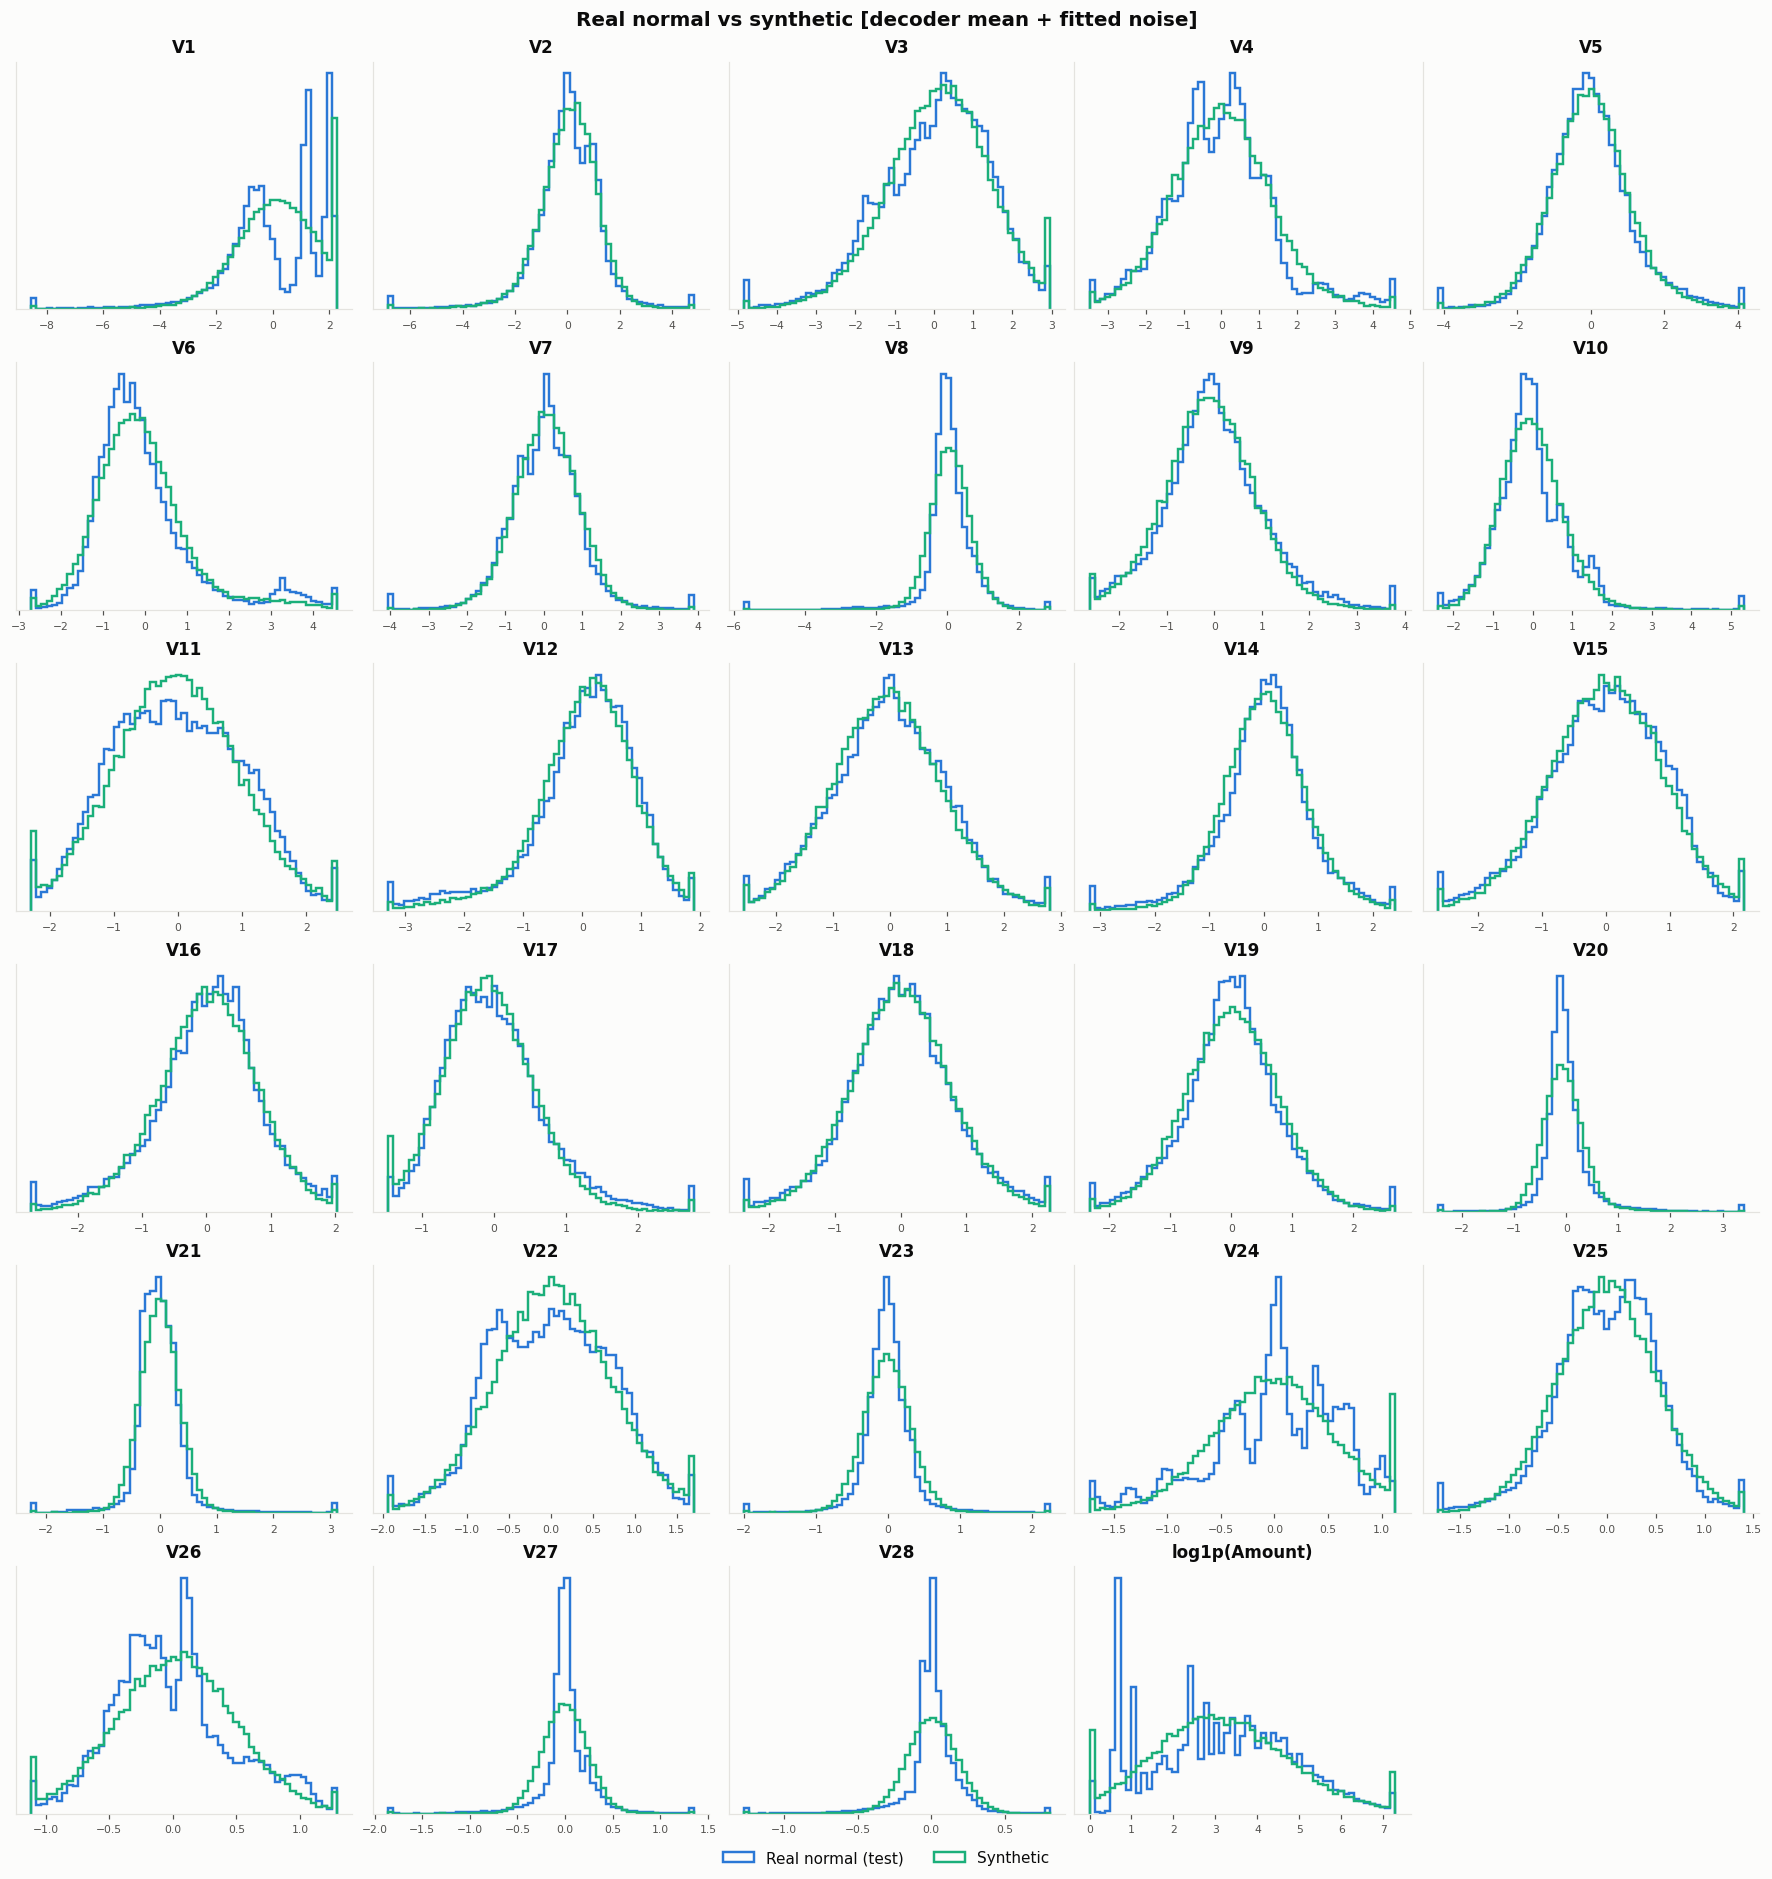

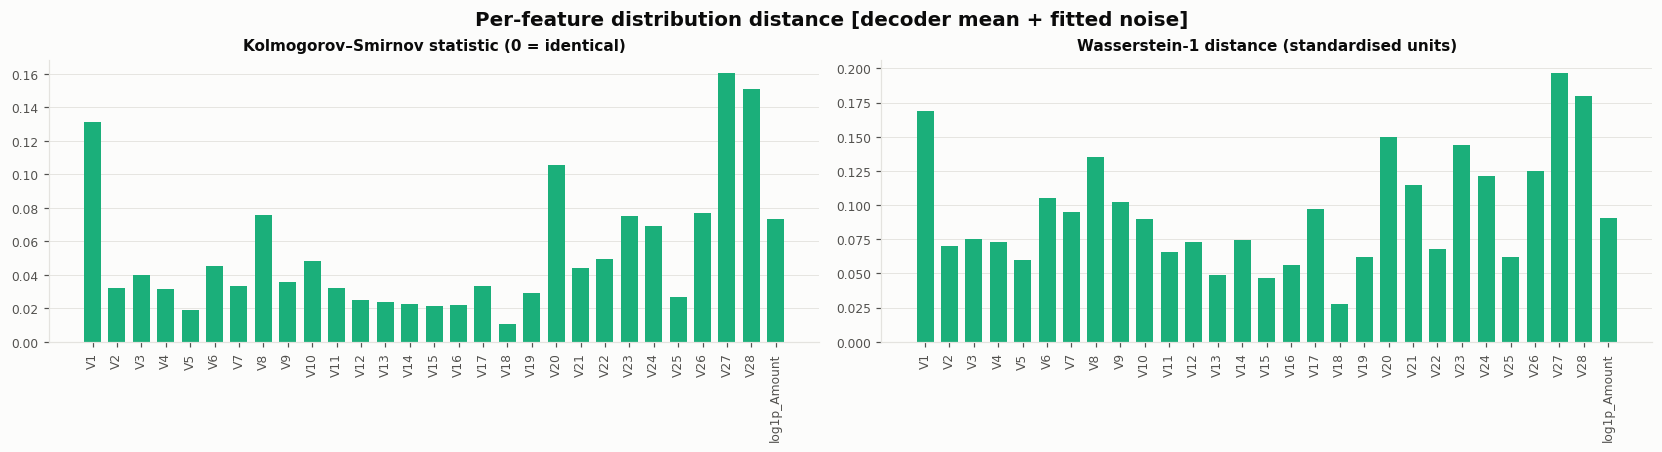

In [11]:
mp.plot_real_vs_synthetic_grid(real, synth["decoder_mean_plus_noise"], "Real normal vs synthetic [decoder mean + fitted noise]")
plt.show()
mp.plot_distance_bars(gm.distance_table(tf.transform(real), tf.transform(synth["decoder_mean_plus_noise"]), tf.feature_names),
                      "Per-feature distribution distance [decoder mean + fitted noise]")
plt.show()

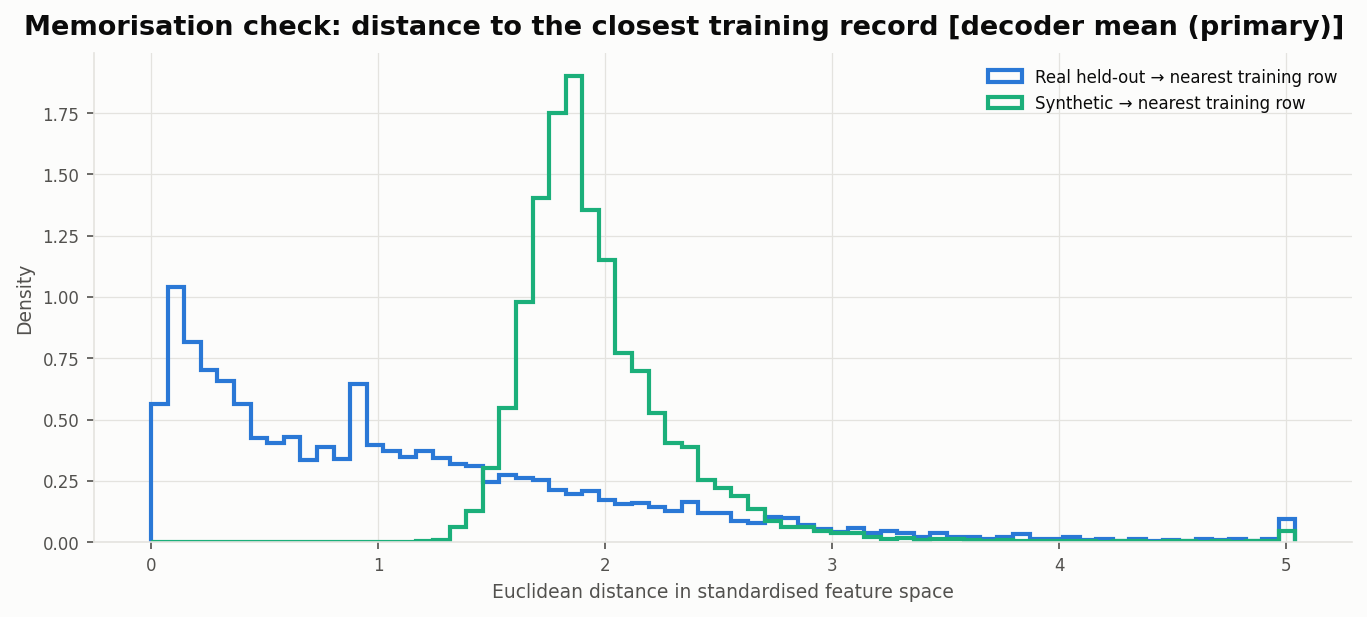

In [12]:
Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "generation" / "decoder_mean_memorisation.png"))

## 6. Assessment of generation quality and limitations

**What works:**
- **Validity:** every exported row is finite, `Amount` is non-negative with 2 decimals, and 99.8% of decoder-mean rows fall inside the real observed range (94.1% for the noise variant).
- **Centre of the distribution:** per-feature means match closely; the average mean error is 0.03 real std for both samplers.
- **Amount relationships (primary sampler):** the decoder mean reproduces the main `Amount` correlations, e.g. Amount–V2 −0.56 against −0.52 real, and Amount–V5 −0.37 against −0.37.
- **No memorisation:** no synthetic row is a copy of a training row. Synthetic rows sit *further* from the training data (median distance 1.89 for decoder mean, 3.10 with noise) than real held-out rows do (0.89).
- **Variant marginals:** with fitted noise, per-feature distributions get much closer. Mean KS falls from 0.221 to 0.053, the std ratio rises from 0.49 to 0.84, and the correlation error halves (Frobenius norm 3.80 → 1.62).

**Limitations:**
1. **Decoder-mean samples are too smooth.** They have about half the real spread (std ratio 0.49) and narrower tails (tail width 0.55). They lie close to an 8-dimensional surface inside the 29-dimensional space, which the PCA plot shows as a thin band. This also adds spurious correlations between V features (mean |r| 0.10 against 0.03 real). This is the known "blurry VAE" behaviour of a Gaussian decoder.
2. **Adding noise has its own cost.** The noise is independent per feature, so it dilutes real dependencies: Amount–V2 falls to −0.17. Noise added in log space inflates `Amount`'s spread 3.9× after `expm1`.
3. **A non-linear classifier easily separates synthetic from real.** Gradient boosting reaches AUC 0.9999 (decoder mean) and 0.991 (noise), against 0.50 for two real samples. So the data matches in simple, first-order respects but not in its full joint structure. The linear (logistic) test is unstable for decoder-mean samples: 0.59 here against normal test rows, but 0.74–0.78 against normal validation rows, because heavy-tailed outliers in the reference sample sway it. The gradient-boosting result is the reliable one.
4. **Heavy tails are under-represented.** Extreme normal transactions are rare in the generated data.
5. **Semantics cannot be checked.** The features are anonymised PCA components, so quality can only be judged statistically. Samples are **not** real or interpretable transactions, and they carry **no fraud label**.
6. **Lower temperature makes things worse.** At temperatures 0.8 and 0.5 the samples shrink further (std ratio 0.32 and 0.15), so temperature 1.0 is kept.

**Bottom line:** the VAE learns the centre and the main linear structure of normal transactions and generates valid, non-memorised vectors. It does not reproduce the full spread, tails or fine joint structure. These synthetic vectors suit demonstrations and teaching about generative modelling. They are not a substitute for real data.